# Texas Road Network — BFS vs A* Search
### Final AI Laboratory: Implementation, Dataset Processing, Accuracy & Performance Evaluation

**Dataset:** Stanford Network Analysis Project (SNAP), `roadNet-TX`  
**Algorithms implemented in this notebook:** Breadth-First Search (BFS) and A* with ALT (landmark/triangle-inequality) heuristic  
**Problem:** Find a valid minimum-hop route between two road-network nodes.

> **Submission design:** This notebook is **standalone**. It does **not** import BFS, A*, or the graph preprocessor from the Streamlit project, and it does not need the project ZIP. Run **Runtime → Run all** in Google Colab. The compressed source dataset is downloaded automatically when missing; you may instead upload `roadNet-TX.txt.gz`.

**Scope and scientific integrity:** SNAP provides road connectivity, **not latitude/longitude, road lengths or travel times**. Every edge is therefore given cost 1, so path cost is measured in **number of roads traversed (hops)**. A geographic Euclidean-distance heuristic would be unsupported; we use exact graph-distance landmarks to construct a mathematically admissible A* heuristic.

**What you will see:** raw-data preprocessing → graph integrity and descriptive statistics → original BFS/A* code → unit tests → independent ground truth → 18 reproducible queries × 3 repetitions × 3 methods → accuracy and search efficiency → memory profiling → plots → statistical analysis → downloadable CSV and figure outputs.

## 1 · Problem formulation & evaluation protocol

- **State:** a road intersection/endpoint, represented by its original SNAP node identifier (mapped internally to a dense array index).
- **Actions:** traverse an undirected edge to an adjacent node.
- **Initial / goal states:** chosen source / destination nodes in the same connected component.
- **Step cost:** 1 per road edge, so total route cost = hop count.
- **BFS:** uninformed, FIFO queue; returns an optimal shortest-hop route in an unweighted graph.
- **A\* (ALT):** informed best-first search with `f(v)=g(v)+h(v)` and a landmark-based lower bound.
- **A\* (`h=0`):** Dijkstra-equivalent control, used to isolate the effect of the heuristic (not an assigned third algorithm).

**Accuracy is NOT classification accuracy.** For reachable benchmark pairs, we report **Optimal-Path Accuracy (%)**: valid edge-by-edge route *and* exactly the same minimum hop cost as an independent SciPy shortest-path calculation. Separately, we measure **Route-Outcome Accuracy** on reachable, disconnected and identical-endpoint test cases. Two different shortest paths of the same hop count are both correct.

| Dimension | Recorded metrics |
|---|---|
| Correctness | found/not found, valid endpoints and edges, independent optimal cost, optimal-path accuracy |
| Solution | path cost (hops), solution depth, number of nodes in returned path |
| Search efficiency | query execution time (ms), nodes expanded, nodes discovered, maximum frontier size, speedup |
| Resource use | algorithm search-state array size, measured process RSS delta in isolated profiling trials |
| Preprocessing | data parsing time, CSR construction time, 8-landmark preprocessing time, total notebook runtime |
| Statistical reliability | repeated runs, per-route median latency, stratified distance classes, source-cluster bootstrap interval |

**Experimental limitations:** sampled queries are a reproducible stratified benchmark, *not* an unbiased sample of all possible Texas routes. Repeated runtime comparisons depend on hardware and Colab load. Offline landmark construction is reported separately from per-query latency.

## 2 · Reproducible environment and source-data acquisition

In [1]:
from pathlib import Path
from dataclasses import dataclass
from collections import deque
import gzip, gc, os, sys, time, math, random, heapq, hashlib, platform, urllib.request, zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path

try:
    import psutil
except ImportError:
    %pip -q install psutil
    import psutil

TOTAL_STARTED = time.perf_counter()
SEED = 2026
N_LANDMARKS = 8
N_SOURCES = 6
REPETITIONS = 3
CATEGORIES = {'Local': (10, 40), 'Regional': (100, 200), 'Long-range': (350, 650)}
RNG = np.random.default_rng(SEED)

IN_COLAB = Path('/content').exists() and 'google.colab' in sys.modules
WORK = Path('/content') if Path('/content').exists() else Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
RESULTS = WORK / 'texas_roadnet_colab_results'
FIGS = RESULTS / 'figures'
FIGS.mkdir(parents=True, exist_ok=True)

SNAP_PAGE = 'https://snap.stanford.edu/data/roadNet-TX.html'
SNAP_FILE = 'https://snap.stanford.edu/data/roadNet-TX.txt.gz'
candidates = [Path('/content/roadNet-TX.txt.gz'), Path('/mnt/data/roadNet-TX.txt.gz'), Path.cwd()/'roadNet-TX.txt.gz', WORK/'roadNet-TX.txt.gz']
DATAFILE = next((p for p in candidates if p.is_file()), None)
if DATAFILE is None:
    DATAFILE = WORK / 'roadNet-TX.txt.gz'
    print('Dataset not found locally; downloading the official Stanford SNAP file...')
    try:
        urllib.request.urlretrieve(SNAP_FILE, DATAFILE)
    except Exception as exc:
        raise RuntimeError('Could not download SNAP. Upload roadNet-TX.txt.gz into Colab Files, then rerun this cell.') from exc

print('Dataset file :', DATAFILE)
print('Compressed MB:', round(DATAFILE.stat().st_size / 1e6, 2))
print('Runtime      :', sys.version.split()[0], platform.platform())
print('NumPy / SciPy:', np.__version__, __import__('scipy').__version__)
print('Logical CPUs :', os.cpu_count())
print('Output folder:', RESULTS)

Dataset file : /mnt/data/roadNet-TX.txt.gz
Compressed MB: 12.44
Runtime      : 3.13.5 Linux-6.18.57-x86_64-with-glibc2.41
NumPy / SciPy: 2.3.5 1.17.0
Logical CPUs : 5
Output folder: /mnt/data/texas_roadnet_colab_results


## 3 · Raw dataset preprocessing and graph integrity

In [2]:
# Build a compact, undirected, unweighted CSR adjacency representation.
# The SNAP text file often stores both orientations of one undirected road.
# Duplicate arcs and self-loops must NOT create repeated roads or weighted edges.

@dataclass
class Graph:
    ids: np.ndarray                # sorted SNAP IDs indexed by internal node index
    indptr: np.ndarray             # CSR start offsets
    indices: np.ndarray            # CSR neighbors
    component: np.ndarray          # connected component membership
    component_sizes: np.ndarray
    largest_component: int

    @property
    def n(self): return len(self.ids)
    @property
    def m(self): return len(self.indices) // 2

    def neighbors(self, v):
        return self.indices[self.indptr[v]:self.indptr[v+1]]

    def node_index(self, snap_id):
        v = int(np.searchsorted(self.ids, snap_id))
        if v == self.n or int(self.ids[v]) != int(snap_id):
            raise ValueError(f'Unknown SNAP ID: {snap_id}')
        return v

    def adjacency(self):
        return csr_matrix((np.ones(len(self.indices), dtype=np.uint8),
                           self.indices, self.indptr), shape=(self.n, self.n))


def graph_from_pairs(pairs):
    p = np.asarray(pairs, dtype=np.int32)
    if p.ndim != 2 or p.shape[1] != 2 or len(p) == 0:
        raise ValueError('Expected nonempty two-column edge list')
    ids = np.unique(p)
    src = np.searchsorted(ids, p[:,0]).astype(np.int32)
    dst = np.searchsorted(ids, p[:,1]).astype(np.int32)
    nonloop = src != dst
    arcs = coo_matrix((np.ones(int(nonloop.sum()), dtype=np.uint8),
                       (src[nonloop], dst[nonloop])), shape=(len(ids),len(ids))).tocsr()
    arcs.sum_duplicates()
    arcs.data[:] = 1                  # all roads have cost 1 (not arc multiplicity)
    adj = arcs.maximum(arcs.T).tocsr()
    adj.setdiag(0)
    adj.eliminate_zeros()
    adj.sort_indices()
    cc_count, labels = connected_components(adj, directed=False)
    sizes = np.bincount(labels, minlength=cc_count).astype(np.int32)
    return Graph(ids.astype(np.int32), adj.indptr.astype(np.int32),
                 adj.indices.astype(np.int32), labels.astype(np.int32), sizes, int(np.argmax(sizes)))


t_load = time.perf_counter()
with gzip.open(DATAFILE, 'rt') as f:
    raw_edges = np.loadtxt(f, comments='#', dtype=np.int32)
parse_sec = time.perf_counter() - t_load
raw_arc_rows = len(raw_edges)
self_loops_in_source = int(np.count_nonzero(raw_edges[:,0] == raw_edges[:,1]))

t_graph = time.perf_counter()
G = graph_from_pairs(raw_edges)
graph_sec = time.perf_counter() - t_graph
# Retain no Python/networkx graph or raw 3.84 million-row edge list in memory.
del raw_edges
gc.collect()

N_EXPECTED, M_EXPECTED, GIANT_EXPECTED = 1_379_917, 1_921_660, 1_351_137
assert (G.n, G.m) == (N_EXPECTED, M_EXPECTED), 'Graph count differs from official SNAP metadata'
assert int(G.component_sizes[G.largest_component]) == GIANT_EXPECTED
assert len(G.indices) == 2 * G.m
assert not np.any(G.indices < 0) and not np.any(G.indices >= G.n)

deg = np.diff(G.indptr)
graph_array_mb = sum(z.nbytes for z in (G.ids, G.indptr, G.indices, G.component, G.component_sizes))/1e6
profile = pd.DataFrame([{
    'nodes': G.n, 'undirected_edges': G.m, 'raw_directed_arc_rows': raw_arc_rows,
    'components': len(G.component_sizes), 'largest_component_nodes': GIANT_EXPECTED,
    'largest_component_percentage': 100*GIANT_EXPECTED/G.n,
    'average_degree': float(deg.mean()), 'median_degree': float(np.median(deg)),
    'maximum_degree': int(deg.max()), 'source_self_loops': self_loops_in_source,
    'CSR_and_label_array_MB': graph_array_mb,
    'parse_seconds': parse_sec, 'graph_construction_seconds': graph_sec
}])
display(profile.T.rename(columns={0:'value'}))
print(f'Raw file parsed in {parse_sec:.2f} s; undirected graph prepared in {graph_sec:.2f} s.')

,value
nodes,1.379917e+06
undirected_edges,1.921660e+06
raw_directed_arc_rows,3.843320e+06
components,4.240000e+02
largest_component_nodes,1.351137e+06
largest_component_percentage,9.791437e+01
average_degree,2.785182e+00
median_degree,3.000000e+00
maximum_degree,1.200000e+01
source_self_loops,0.000000e+00


Raw file parsed in 1.08 s; undirected graph prepared in 1.24 s.


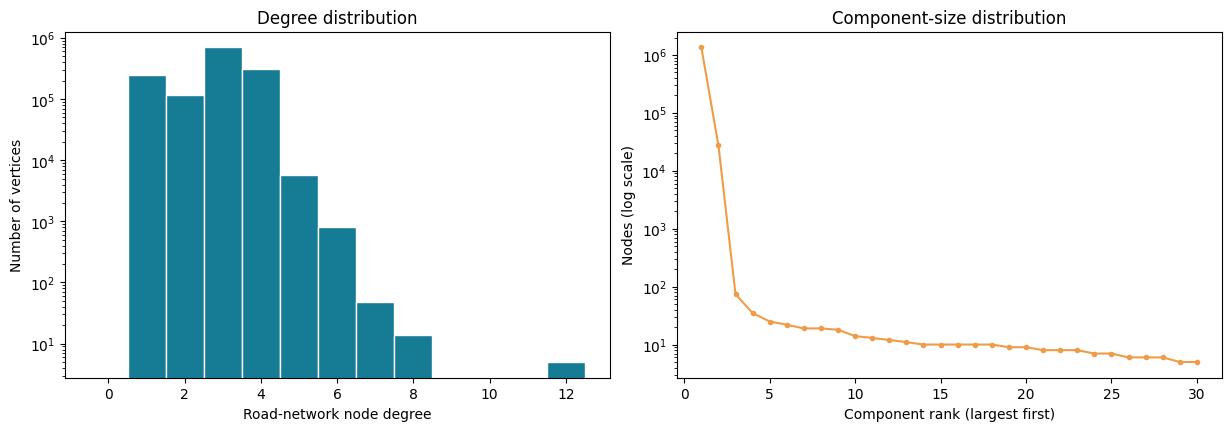

In [3]:
# Basic descriptive plots; these are graph properties, not physical Texas coordinates.
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2), layout='constrained')
axes[0].hist(deg, bins=np.arange(0, int(deg.max())+2)-.5, color='#167b94', edgecolor='white')
axes[0].set(xlabel='Road-network node degree', ylabel='Number of vertices', title='Degree distribution')
axes[0].set_yscale('log')
axes[1].plot(np.arange(1, min(31, len(G.component_sizes)+1)),
             np.sort(G.component_sizes)[::-1][:30], marker='o', markersize=3, color='#ee9c48')
axes[1].set(xlabel='Component rank (largest first)', ylabel='Nodes (log scale)', title='Component-size distribution')
axes[1].set_yscale('log')
fig.savefig(FIGS/'01_graph_profile.png', dpi=170, bbox_inches='tight')
plt.show()

## 4 · ALT landmark preprocessing: the admissible A* heuristic

For the undirected, unit-cost graph, let `d(L,v)` be the exact number of edges in the shortest route from landmark `L` to vertex `v`. Use:

\[
h(v,t)=\max_{L \in \mathcal L}\left|d(L,t)-d(L,v)\right|.
\]

By the triangle inequality, each term is at most `d(v,t)`, hence **h is admissible**. For every edge `(u,v)`, `|h(u,t)-h(v,t)| ≤ 1`, so the heuristic is also **consistent**. A* therefore returns an optimal minimum-hop route.

We select eight landmark vertices using deterministic **farthest-first traversal** within the giant connected component. SciPy is used **only to compute the offline landmark distance index and independent validation distances**; our BFS/A* search loops below are implemented from scratch. The preprocessing cost is measured and **excluded** from online query latency. Outside the giant component, `h = 0` safely reduces A* to Dijkstra behavior.

In [4]:
@dataclass
class LandmarkIndex:
    landmark_nodes: np.ndarray     # internal indices of landmarks
    distance: np.ndarray           # shape (k, |V|), uint16 with sentinel for unreachable

    @property
    def unreachable(self): return int(np.iinfo(self.distance.dtype).max)

    def at(self, v, target):
        max_lower = 0
        for row in self.distance:
            a, b = int(row[v]), int(row[target])
            if a != self.unreachable and b != self.unreachable:
                max_lower = max(max_lower, abs(a-b))
        return max_lower

    def for_target(self, target):
        """Vectorized full potential; vectorizing has a per-query setup cost."""
        out = np.zeros(self.distance.shape[1], dtype=np.int32)
        for row in self.distance:
            dt = int(row[target])
            if dt == self.unreachable: continue
            valid = (row != self.unreachable)
            out[valid] = np.maximum(out[valid], np.abs(row[valid].astype(np.int32)-dt))
        return out


def build_landmark_index(graph, count=8):
    adj = graph.adjacency()
    largest = (graph.component == graph.largest_component)
    candidates = np.flatnonzero(largest)
    degree = np.diff(graph.indptr)
    next_node = int(candidates[np.argmax(degree[candidates])])
    nearest_landmark_dist = np.full(graph.n, np.inf, dtype=np.float64)
    selected, distance_rows = [], []
    for k in range(count):
        selected.append(next_node)
        distances = shortest_path(adj, directed=False, unweighted=True, indices=next_node)
        assert np.isfinite(distances[largest]).all()
        assert np.nanmax(distances[np.isfinite(distances)]) < 65535, 'uint16 distance encoding would overflow'
        encoded = np.full(graph.n, np.iinfo(np.uint16).max, dtype=np.uint16)
        finite = np.isfinite(distances)
        encoded[finite] = distances[finite].astype(np.uint16)
        distance_rows.append(encoded)
        nearest_landmark_dist = np.minimum(nearest_landmark_dist, distances)
        if k < count-1:
            scores = nearest_landmark_dist.copy()
            scores[~largest] = -1
            scores[np.array(selected, dtype=np.int32)] = -1
            next_node = int(np.argmax(scores))
        print(f'  Landmark {k+1}/{count}: original node {int(graph.ids[selected[-1]])}')
    return LandmarkIndex(np.array(selected, dtype=np.int32), np.stack(distance_rows))

landmark_started = time.perf_counter()
LM = build_landmark_index(G, N_LANDMARKS)
landmark_sec = time.perf_counter() - landmark_started
print(f'Offline ALT index built in {landmark_sec:.2f} s; stored landmark table: {LM.distance.nbytes/1e6:.2f} MB')
print('Landmark IDs:', G.ids[LM.landmark_nodes].tolist())

  Landmark 1/8: original node 126099


  Landmark 2/8: original node 198933


  Landmark 3/8: original node 437148


  Landmark 4/8: original node 878306


  Landmark 5/8: original node 1123214


  Landmark 6/8: original node 1245374


  Landmark 7/8: original node 1215721


  Landmark 8/8: original node 1051551
Offline ALT index built in 3.50 s; stored landmark table: 22.08 MB
Landmark IDs: [126099, 198933, 437148, 878306, 1123214, 1245374, 1215721, 1051551]


## 5 · Implemented BFS and A* algorithms (not library pathfinding calls)

In [5]:
@dataclass
class SearchResult:
    algorithm: str
    source: int                 # INTERNAL node index
    target: int
    found: bool
    path: list                 # INTERNAL vertex indices
    hops: int | None
    expanded: int
    discovered: int
    peak_frontier: int
    time_ms: float
    search_arrays_mb: float    # NumPy arrays only; not the heap/queue or graph
    heuristic_source: int = 0


def make_path(parent, source, target):
    path = [target]
    while path[-1] != source:
        ancestor = int(parent[path[-1]])
        if ancestor == -1: raise AssertionError('Predecessor chain is broken')
        path.append(ancestor)
    return path[::-1]


def bfs(graph, source, target):
    """Unit-weight BFS: shortest-hop exact search with a FIFO deque."""
    started = time.perf_counter()
    if source == target:
        return SearchResult('BFS', source, target, True, [source], 0, 1, 1, 1,
                            (time.perf_counter()-started)*1000, 0.0)
    if graph.component[source] != graph.component[target]:
        return SearchResult('BFS', source, target, False, [], None, 0, 0, 0,
                            (time.perf_counter()-started)*1000, 0.0)

    parent = np.full(graph.n, -1, dtype=np.int32)
    parent[source] = source               # also serves as visited marker
    queue = deque([source])
    expanded, discovered, peak = 0, 1, 1
    while queue:
        v = queue.popleft()
        expanded += 1
        if v == target:
            path = make_path(parent, source, target)
            return SearchResult('BFS', source, target, True, path, len(path)-1,
                                expanded, discovered, peak, (time.perf_counter()-started)*1000,
                                parent.nbytes/1e6)
        for u_raw in graph.neighbors(v):
            u = int(u_raw)
            if parent[u] == -1:
                parent[u] = v
                queue.append(u)
                discovered += 1
        peak = max(peak, len(queue))
    raise AssertionError('Components said reachable but BFS found no route')


def astar(graph, source, target, landmarks=None, use_heuristic=True):
    """A* with a consistent ALT lower bound; h=0 gives a Dijkstra control."""
    started = time.perf_counter()
    label = 'A* (ALT)' if use_heuristic else 'A* (h=0)'
    if source == target:
        return SearchResult(label, source, target, True, [source], 0, 1, 1, 1,
                            (time.perf_counter()-started)*1000, 0.0)
    if graph.component[source] != graph.component[target]:
        return SearchResult(label, source, target, False, [], None, 0, 0, 0,
                            (time.perf_counter()-started)*1000, 0.0)
    if use_heuristic and landmarks is None:
        raise ValueError('ALT requires a landmark index')
    if use_heuristic:
        h_start = landmarks.at(source, target)
        # Lazy h for short routes avoids allocating/calculating 1.38m heuristic values.
        h_vector = None if h_start <= 40 else landmarks.for_target(target)
        heuristic = (lambda v: landmarks.at(v,target)) if h_vector is None else (lambda v: int(h_vector[v]))
    else:
        h_start = 0
        h_vector = None
        heuristic = lambda v: 0

    inf = np.iinfo(np.int32).max
    best_g = np.full(graph.n, inf, dtype=np.int32)
    parent = np.full(graph.n, -1, dtype=np.int32)
    settled = np.zeros(graph.n, dtype=np.bool_)
    best_g[source] = 0
    # second heap key = -g; consistent h + deeper-first tie breaking is optimal.
    frontier = [(h_start, 0, source)]
    expanded, discovered, peak = 0, 1, 1
    while frontier:
        priority, negative_g, v = heapq.heappop(frontier)
        g = -negative_g
        if settled[v] or g != best_g[v]:  # stale heap entry
            continue
        settled[v] = True
        expanded += 1
        if v == target:
            path = make_path(parent, source, target)
            arrays = best_g.nbytes + parent.nbytes + settled.nbytes
            if h_vector is not None: arrays += h_vector.nbytes
            return SearchResult(label, source, target, True, path, len(path)-1,
                                expanded, discovered, peak, (time.perf_counter()-started)*1000,
                                arrays/1e6, h_start)
        for u_raw in graph.neighbors(v):
            u = int(u_raw)
            trial_g = g+1
            if not settled[u] and trial_g < best_g[u]:
                if best_g[u] == inf: discovered += 1
                best_g[u] = trial_g
                parent[u] = v
                heapq.heappush(frontier, (trial_g + heuristic(u), -trial_g, u))
        peak = max(peak, len(frontier))
    raise AssertionError('Components said reachable but A* found no route')

## 6 · Independent correctness checks and edge cases

In [6]:
def valid_route(graph, result):
    if not result.found:
        return result.path == [] and result.hops is None
    path = result.path
    if not path or path[0] != result.source or path[-1] != result.target:
        return False
    if result.hops != len(path)-1:
        return False
    for a,b in zip(path,path[1:]):
        neighbors = graph.neighbors(a)
        where = np.searchsorted(neighbors, b)
        if where == len(neighbors) or int(neighbors[where]) != b:
            return False
    return True

# Micrograph: duplicate input arcs, a cycle, a disconnected edge, and a self-loop.
mini_edges = np.array([[10,20],[20,10],[10,20],[10,30],[20,40],[30,40],[100,200],[20,20]], dtype=np.int32)
SMALL = graph_from_pairs(mini_edges)
assert SMALL.n == 6 and SMALL.m == 5
mini_s, mini_t = SMALL.node_index(10), SMALL.node_index(40)
for algorithm in (lambda a,b: bfs(SMALL,a,b), lambda a,b: astar(SMALL,a,b,use_heuristic=False)):
    res = algorithm(mini_s, mini_t)
    assert res.found and res.hops == 2 and valid_route(SMALL,res)
    assert algorithm(mini_s,mini_s).hops == 0
    assert not algorithm(mini_s,SMALL.node_index(100)).found

# ALT correctness on the full graph: heuristic zero at target; edges satisfy consistency.
example_target = int(np.flatnonzero(G.component == G.largest_component)[12345])
h_example = LM.for_target(example_target)
assert h_example[example_target] == 0
heur_rng = np.random.default_rng(713)
sampled_arc_locations = heur_rng.integers(0,len(G.indices),size=12_000)
arc_sources = np.searchsorted(G.indptr, sampled_arc_locations, side='right')-1
arc_destinations = G.indices[sampled_arc_locations]
assert np.all(np.abs(h_example[arc_sources]-h_example[arc_destinations]) <= 1)
# Independent reference: for 40 random same-component vertices, h cannot exceed real d.
adjacency = G.adjacency()
reference_example = shortest_path(adjacency, directed=False, unweighted=True, indices=example_target)
sample_nodes = heur_rng.choice(np.flatnonzero(np.isfinite(reference_example)), size=40, replace=False)
assert np.all(h_example[sample_nodes] <= reference_example[sample_nodes])
print('PASS: synthetic graph cases, BFS shortest route, Dijkstra control, duplicates, self-loops,')
print('      disconnected nodes, source=target, ALT consistency on 12,000 arcs and sampled admissibility.')

PASS: synthetic graph cases, BFS shortest route, Dijkstra control, duplicates, self-loops,
      disconnected nodes, source=target, ALT consistency on 12,000 arcs and sampled admissibility.


## 7 · Fair benchmark design and independent shortest-path reference

We sample six source nodes from the largest component with a fixed random seed. For each source, SciPy's **independent** unweighted shortest-path routine obtains exact distances to the entire graph and chooses one destination from each predeclared distance band: **Local 10–40**, **Regional 100–200**, **Long-range 350–650** hops. This yields **18 different reachable routes**. Distances used to define/verify the cases are not supplied to the BFS or A* search functions.

Every route is run using both assigned algorithms and an `h=0` control, with **three repeated timings each**. Method order is shuffled within every repetition to reduce order effects; one warmup query is excluded from timing. **All 162 search executions are checked** for correct path edges and minimum hop cost.

In [7]:
sampling_started = time.perf_counter()
giant_nodes = np.flatnonzero(G.component == G.largest_component)
# Choose sources first, then independently generate ground-truth distance arrays.
sources = RNG.choice(giant_nodes, size=N_SOURCES, replace=False)
route_cases = []
exact_by_source = {}
for source_no, s_np in enumerate(sources, 1):
    s = int(s_np)
    d = shortest_path(adjacency, directed=False, unweighted=True, indices=s)
    exact_by_source[s] = d
    for category, (low, high) in CATEGORIES.items():
        choices = np.flatnonzero((d >= low) & (d <= high) & np.isfinite(d))
        assert len(choices) > 0, f'No targets in {category} for source {int(G.ids[s])}'
        t = int(RNG.choice(choices))
        route_cases.append(dict(case_id=len(route_cases)+1, category=category,
                                source_index=s, target_index=t,
                                source_snap=int(G.ids[s]), target_snap=int(G.ids[t]),
                                reference_hops=int(d[t])))
cases_df = pd.DataFrame(route_cases)
reference_sampling_sec = time.perf_counter()-sampling_started
assert len(cases_df) == N_SOURCES*len(CATEGORIES)
print(f'Generated {len(cases_df)} exact-reference routes from {N_SOURCES} sources in {reference_sampling_sec:.2f} s.')
display(cases_df[['case_id','category','source_snap','target_snap','reference_hops']])

Generated 18 exact-reference routes from 6 sources in 2.32 s.


,case_id,category,source_snap,target_snap,reference_hops
0,1,Local,662101,659486,36
1,2,Regional,662101,954246,121
2,3,Long-range,662101,1301725,527
3,4,Local,898351,970079,14
4,5,Regional,898351,22786,167
5,6,Long-range,898351,1152613,499
6,7,Local,522621,533826,28
7,8,Regional,522621,396345,125
8,9,Long-range,522621,339143,528
9,10,Local,36397,33092,24


## 8 · Run all three search methods, collect every measured result

In [8]:
METHODS = {
    'BFS': lambda s,t: bfs(G,s,t),
    'A* (ALT)': lambda s,t: astar(G,s,t,LM,True),
    'A* (h=0)': lambda s,t: astar(G,s,t,LM,False)
}
# Warmup is excluded from all reported data.
warmup = route_cases[0]
for name, fn in METHODS.items():
    trial = fn(warmup['source_index'], warmup['target_index'])
    assert valid_route(G,trial) and trial.hops==warmup['reference_hops']

timing_started = time.perf_counter()
trial_rows=[]
trial_order = [(int(c['case_id']),r,alg) for c in route_cases for r in range(1,REPETITIONS+1) for alg in METHODS]
np.random.default_rng(SEED+13).shuffle(trial_order)
case_lookup = {int(c['case_id']):c for c in route_cases}
for j,(case_id,repeat,alg) in enumerate(trial_order,1):
    case = case_lookup[case_id]
    result = METHODS[alg](case['source_index'],case['target_index'])
    path_valid = valid_route(G,result)
    optimal = bool(result.found and path_valid and result.hops == case['reference_hops'])
    assert optimal, f'Incorrect route for {alg}: case {case_id}, run {repeat}'
    trial_rows.append({
        'case_id':case_id, 'category':case['category'],
        'source_snap':case['source_snap'], 'target_snap':case['target_snap'],
        'reference_hops':case['reference_hops'],
        'algorithm':alg, 'repetition':repeat,
        'found':result.found, 'path_valid':path_valid, 'optimal':optimal,
        'optimal_path_accuracy_score':int(optimal),
        'returned_hops':result.hops, 'path_nodes':len(result.path),
        'query_time_ms':result.time_ms, 'nodes_expanded':result.expanded,
        'nodes_discovered':result.discovered, 'peak_frontier':result.peak_frontier,
        'search_arrays_MB':result.search_arrays_mb,
        'initial_ALT_lower_bound':result.heuristic_source
    })
    if j % 27==0:
        print(f'Validated {j}/{len(trial_order)} searches')
trials = pd.DataFrame(trial_rows).sort_values(['case_id','algorithm','repetition']).reset_index(drop=True)
benchmark_wall_sec = time.perf_counter()-timing_started
assert len(trials)==N_SOURCES*len(CATEGORIES)*len(METHODS)*REPETITIONS
print(f'PASS: {len(trials)} individually validated executions; complete timed experiment: {benchmark_wall_sec:.2f} s')
display(trials.head(9))

Validated 27/162 searches


Validated 54/162 searches


Validated 81/162 searches


Validated 108/162 searches


Validated 135/162 searches


Validated 162/162 searches
PASS: 162 individually validated executions; complete timed experiment: 134.64 s


,case_id,category,source_snap,target_snap,reference_hops,algorithm,repetition,found,path_valid,optimal,optimal_path_accuracy_score,returned_hops,path_nodes,query_time_ms,nodes_expanded,nodes_discovered,peak_frontier,search_arrays_MB,initial_ALT_lower_bound
0,1,Local,662101,659486,36,A* (ALT),1,True,True,True,1,36,37,11.850229,108,188,90,12.419253,32
1,1,Local,662101,659486,36,A* (ALT),2,True,True,True,1,36,37,4.560164,108,188,90,12.419253,32
2,1,Local,662101,659486,36,A* (ALT),3,True,True,True,1,36,37,4.757768,108,188,90,12.419253,32
3,1,Local,662101,659486,36,A* (h=0),1,True,True,True,1,36,37,17.999003,3800,4073,275,12.419253,0
4,1,Local,662101,659486,36,A* (h=0),2,True,True,True,1,36,37,13.338551,3800,4073,275,12.419253,0
5,1,Local,662101,659486,36,A* (h=0),3,True,True,True,1,36,37,13.791354,3800,4073,275,12.419253,0
6,1,Local,662101,659486,36,BFS,1,True,True,True,1,36,37,8.526078,3729,3988,268,5.519668,0
7,1,Local,662101,659486,36,BFS,2,True,True,True,1,36,37,8.981294,3729,3988,268,5.519668,0
8,1,Local,662101,659486,36,BFS,3,True,True,True,1,36,37,7.482818,3729,3988,268,5.519668,0


## 9 · Accuracy, shortest-path correctness, search success

We report **Optimal-Path Accuracy (%)** on the 18 reachable cases, using independent reference distances and checking **every consecutive returned edge**. We do not call it prediction accuracy, since there is no class label or supervised model. For disconnected pairs, returning **no route** is the correct answer. Identical source and target should return a zero-hop route.

In [9]:
accuracy = (trials.groupby('algorithm',as_index=False)
    .agg(executions=('optimal','size'), valid_paths=('path_valid','sum'),
         shortest_optimal_paths=('optimal','sum'), successful_searches=('found','sum')))
accuracy['Optimal-path accuracy (%)'] = 100*accuracy.shortest_optimal_paths/accuracy.executions
accuracy['Valid-route rate (%)'] = 100*accuracy.valid_paths/accuracy.executions
accuracy['Search success (%)'] = 100*accuracy.successful_searches/accuracy.executions

display(accuracy)
assert (accuracy['Optimal-path accuracy (%)']==100).all()
print('Interpretation: 100% means ALL evaluated reachable test queries returned a valid optimal route;')
print('it does not claim 100% performance on every possible pair in Texas.')

# Additional outcome-accuracy tests, including disconnected pairs and identical endpoints.
other_cc = np.flatnonzero(G.component != G.largest_component)
assert len(other_cc) > 0
special_cases = [
    (int(sources[0]),int(sources[0]),True,0,'same source and destination'),
    (int(sources[0]),int(other_cc[0]),False,None,'disconnected components'),
    (int(other_cc[0]),int(sources[0]),False,None,'reverse disconnected query')
]
special_rows=[]
for s,t,expected_found,expected_hops,scenario in special_cases:
    for alg,fn in METHODS.items():
        res = fn(s,t)
        pass_test = (res.found==expected_found and res.hops==expected_hops and valid_route(G,res))
        special_rows.append(dict(scenario=scenario, algorithm=alg,
                                 expected_found=expected_found, predicted_found=res.found,
                                 returned_hops=res.hops, correct=pass_test))
special_df=pd.DataFrame(special_rows)
assert special_df.correct.all()
print(f'Route-outcome accuracy on special test cases: {special_df.correct.mean()*100:.1f}% ({special_df.correct.sum()}/{len(special_df)})')
display(special_df)

,algorithm,executions,valid_paths,shortest_optimal_paths,successful_searches,Optimal-path accuracy (%),Valid-route rate (%),Search success (%)
0,A* (ALT),54,54,54,54,100.0,100.0,100.0
1,A* (h=0),54,54,54,54,100.0,100.0,100.0
2,BFS,54,54,54,54,100.0,100.0,100.0


Interpretation: 100% means ALL evaluated reachable test queries returned a valid optimal route;
it does not claim 100% performance on every possible pair in Texas.
Route-outcome accuracy on special test cases: 100.0% (9/9)


,scenario,algorithm,expected_found,predicted_found,returned_hops,correct
0,same source and destination,BFS,True,True,0.0,True
1,same source and destination,A* (ALT),True,True,0.0,True
2,same source and destination,A* (h=0),True,True,0.0,True
3,disconnected components,BFS,False,False,NaN,True
4,disconnected components,A* (ALT),False,False,NaN,True
5,disconnected components,A* (h=0),False,False,NaN,True
6,reverse disconnected query,BFS,False,False,NaN,True
7,reverse disconnected query,A* (ALT),False,False,NaN,True
8,reverse disconnected query,A* (h=0),False,False,NaN,True


## 10 · Per-route results, time complexity in practice, and speedup

In [10]:
# Repetition-level records remain available in trials. Use paired per-route MEDIANS for comparison.
per_route = (trials.groupby(['case_id','category','source_snap','target_snap','reference_hops','algorithm'],as_index=False)
    .agg(median_ms=('query_time_ms','median'), min_ms=('query_time_ms','min'),
         max_ms=('query_time_ms','max'), mean_ms=('query_time_ms','mean'),
         expanded=('nodes_expanded','median'), discovered=('nodes_discovered','median'),
         peak_frontier=('peak_frontier','median'), search_arrays_MB=('search_arrays_MB','median'),
         path_hops=('returned_hops','median'), optimal=('optimal','all'),
         h_source=('initial_ALT_lower_bound','median')))

wide = per_route.pivot(index=['case_id','category','source_snap','target_snap','reference_hops'],
                       columns='algorithm',values=['median_ms','expanded','discovered','peak_frontier','search_arrays_MB','h_source'])
wide.columns = [f'{col}_{alg}' for col,alg in wide.columns]
paired=wide.reset_index()
paired['speedup_BFS_over_Astar'] = paired['median_ms_BFS']/paired['median_ms_A* (ALT)']
paired['expanded_reduction_pct'] = 100*(1-paired['expanded_A* (ALT)']/paired['expanded_BFS'])
paired['discovered_reduction_pct'] = 100*(1-paired['discovered_A* (ALT)']/paired['discovered_BFS'])
paired['frontier_reduction_pct'] = 100*(1-paired['peak_frontier_A* (ALT)']/paired['peak_frontier_BFS'])
paired['heuristic_tightness'] = paired['h_source_A* (ALT)']/paired['reference_hops']

summary_by_category = (paired.groupby('category',as_index=False)
    .agg(routes=('case_id','count'), median_BFS_ms=('median_ms_BFS','median'),
         median_Astar_ms=('median_ms_A* (ALT)','median'),
         median_speedup=('speedup_BFS_over_Astar','median'),
         median_node_reduction_pct=('expanded_reduction_pct','median'),
         median_hops=('reference_hops','median'),
         Astar_faster=('speedup_BFS_over_Astar',lambda x: int((x>1).sum()))))
summary_by_category['category'] = pd.Categorical(summary_by_category.category, categories=list(CATEGORIES),ordered=True)
summary_by_category = summary_by_category.sort_values('category')

print('PAIRED SUMMARY (median of each route’s three timing repetitions):')
display(paired[['case_id','category','reference_hops','median_ms_BFS','median_ms_A* (ALT)',
                'speedup_BFS_over_Astar','expanded_BFS','expanded_A* (ALT)','expanded_reduction_pct']].round(2))
print('BY DISTANCE CLASS:')
display(summary_by_category.round(2))
print('OVERALL:')
print(f'  Median paired speedup BFS / ALT A*: {paired.speedup_BFS_over_Astar.median():.2f}x')
print(f'  Median nodes-expanded reduction     : {paired.expanded_reduction_pct.median():.1f}%')
print(f'  A* faster on {int((paired.speedup_BFS_over_Astar>1).sum())} / {len(paired)} queries')

PAIRED SUMMARY (median of each route’s three timing repetitions):


,case_id,category,reference_hops,median_ms_BFS,median_ms_A* (ALT),speedup_BFS_over_Astar,expanded_BFS,expanded_A* (ALT),expanded_reduction_pct
0,1,Local,36,8.53,4.76,1.79,3729.0,108.0,97.10
1,2,Regional,121,127.33,77.30,1.65,62050.0,2960.0,95.23
2,3,Long-range,527,3543.65,211.58,16.75,1259659.0,31368.0,97.51
3,4,Local,14,1.94,4.13,0.47,771.0,88.0,88.59
4,5,Regional,167,245.49,132.88,1.85,113843.0,18471.0,83.78
5,6,Long-range,499,1517.64,329.53,4.61,662540.0,68176.0,89.71
6,7,Local,28,7.30,10.21,0.72,3175.0,321.0,89.89
7,8,Regional,125,361.14,103.50,3.49,148131.0,9453.0,93.62
8,9,Long-range,528,1990.12,821.12,2.42,880702.0,169989.0,80.70
9,10,Local,24,5.01,5.58,0.90,1760.0,151.0,91.42


BY DISTANCE CLASS:


,category,routes,median_BFS_ms,median_Astar_ms,median_speedup,median_node_reduction_pct,median_hops,Astar_faster
0,Local,6,6.16,5.17,1.08,93.76,26.0,3
2,Regional,6,226.70,95.15,2.12,93.44,125.5,5
1,Long-range,6,2245.57,254.55,10.68,93.76,513.0,6


OVERALL:
  Median paired speedup BFS / ALT A*: 2.12x
  Median nodes-expanded reduction     : 93.4%
  A* faster on 14 / 18 queries


## 11 · Plot the results (actual measured timings and searches)

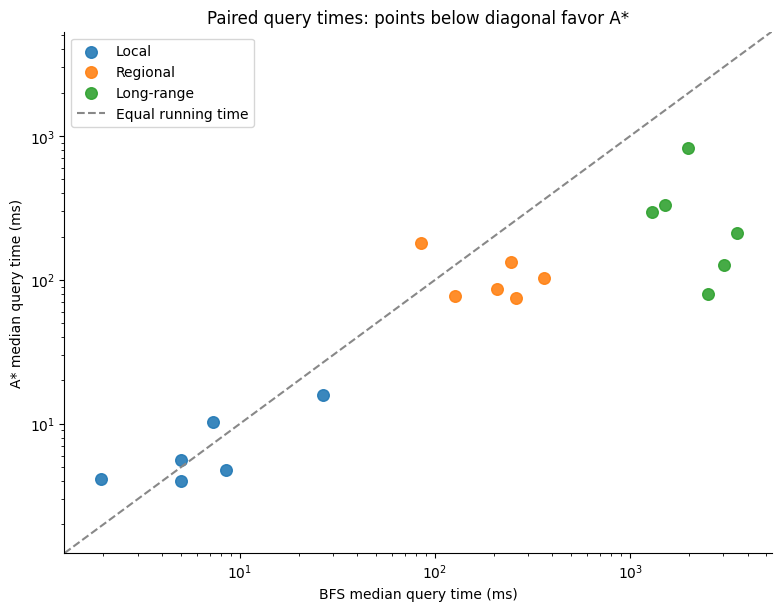

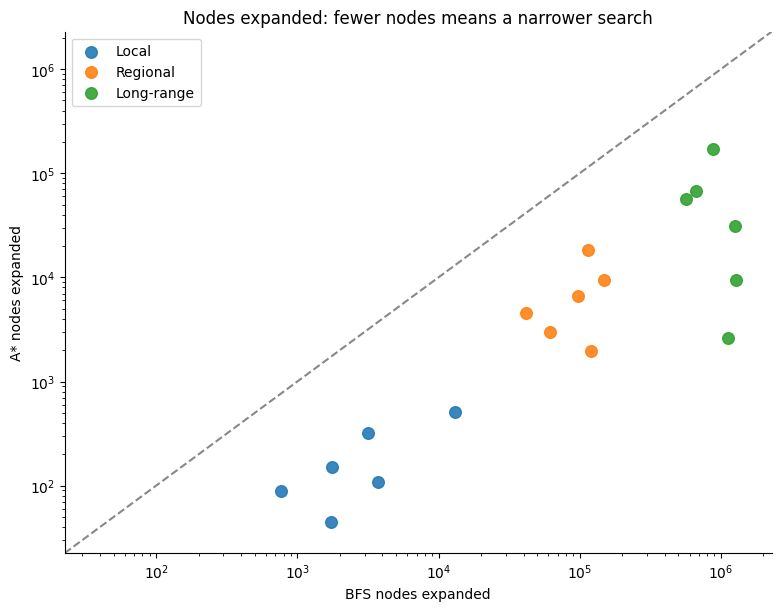

In [11]:
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
PALETTE = {'BFS':'#147c90','A* (ALT)':'#e19a3b','A* (h=0)':'#8a71bc'}

fig,ax=plt.subplots(figsize=(7.7,6.0),layout='constrained')
for cat, sub in paired.groupby('category',sort=False):
    ax.scatter(sub['median_ms_BFS'],sub['median_ms_A* (ALT)'],s=70,label=cat,alpha=.88)
all_vals=np.r_[paired['median_ms_BFS'].values,paired['median_ms_A* (ALT)'].values]
lo=max(np.min(all_vals)*.65,.01); hi=np.max(all_vals)*1.5
ax.plot([lo,hi],[lo,hi],'--',color='#888888',label='Equal running time')
ax.set(xscale='log',yscale='log',xlim=(lo,hi),ylim=(lo,hi),
       xlabel='BFS median query time (ms)',ylabel='A* median query time (ms)',
       title='Paired query times: points below diagonal favor A*')
ax.legend()
fig.savefig(FIGS/'02_query_time_scatter.png',dpi=170,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(figsize=(7.7,6.0),layout='constrained')
for cat,sub in paired.groupby('category',sort=False):
    ax.scatter(sub.expanded_BFS,sub['expanded_A* (ALT)'],s=70,label=cat,alpha=.88)
low=max(1,min(paired['expanded_A* (ALT)'].min(),paired.expanded_BFS.min())*.5)
high=max(paired.expanded_BFS.max(),paired['expanded_A* (ALT)'].max())*1.8
ax.plot([low,high],[low,high],'--',color='#888888')
ax.set(xscale='log',yscale='log',xlim=(low,high),ylim=(low,high),
       xlabel='BFS nodes expanded',ylabel='A* nodes expanded',
       title='Nodes expanded: fewer nodes means a narrower search')
ax.legend()
fig.savefig(FIGS/'03_expanded_nodes_scatter.png',dpi=170,bbox_inches='tight')
plt.show()

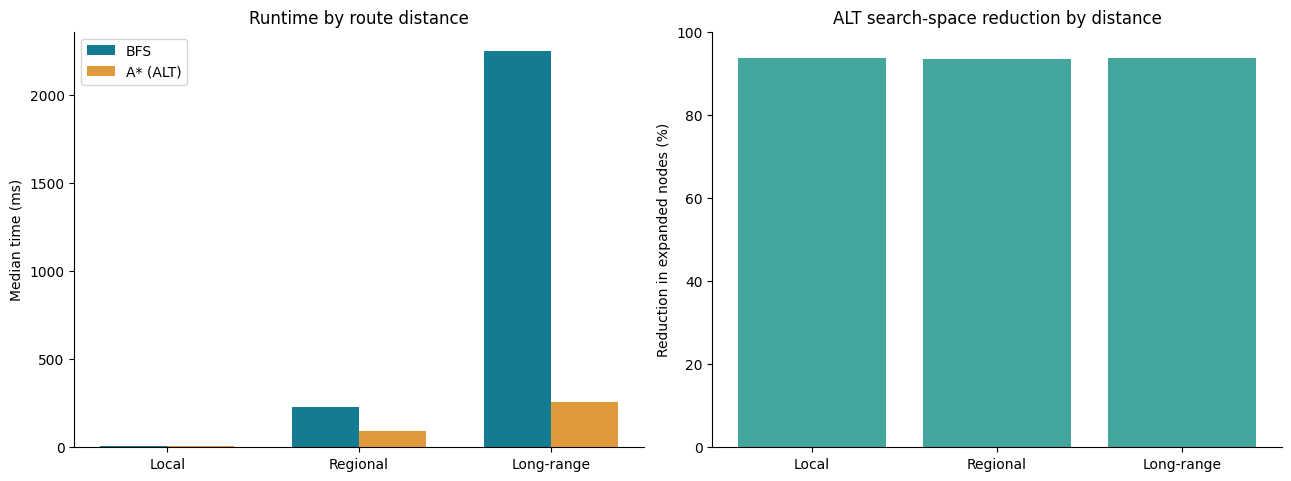

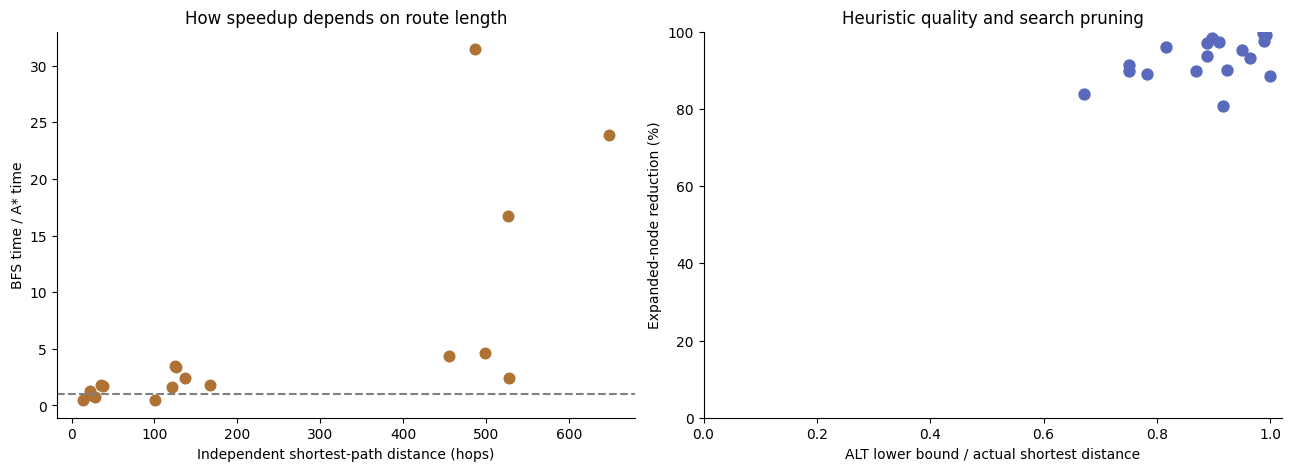

In [12]:
fig,axs=plt.subplots(1,2,figsize=(12.8,4.7),layout='constrained')
cats=list(CATEGORIES)
locs=np.arange(len(cats)); width=.35
bfs_med=summary_by_category.set_index('category').loc[cats,'median_BFS_ms'].to_numpy()
as_med=summary_by_category.set_index('category').loc[cats,'median_Astar_ms'].to_numpy()
axs[0].bar(locs-width/2,bfs_med,width,color=PALETTE['BFS'],label='BFS')
axs[0].bar(locs+width/2,as_med,width,color=PALETTE['A* (ALT)'],label='A* (ALT)')
axs[0].set(xticks=locs,xticklabels=cats,ylabel='Median time (ms)',title='Runtime by route distance')
axs[0].legend()
axs[1].bar(locs,summary_by_category.set_index('category').loc[cats,'median_node_reduction_pct'],color='#42a69c')
axs[1].set(xticks=locs,xticklabels=cats,ylim=(0,100),ylabel='Reduction in expanded nodes (%)',
           title='ALT search-space reduction by distance')
fig.savefig(FIGS/'04_distance_class_comparison.png',dpi=170,bbox_inches='tight')
plt.show()

fig,axs=plt.subplots(1,2,figsize=(12.8,4.6),layout='constrained')
ordered=paired.sort_values('reference_hops')
axs[0].scatter(ordered.reference_hops,ordered.speedup_BFS_over_Astar,color='#ae7234',s=58)
axs[0].axhline(1,color='gray',ls='--')
axs[0].set(xlabel='Independent shortest-path distance (hops)',ylabel='BFS time / A* time',
           title='How speedup depends on route length')
axs[1].scatter(paired.heuristic_tightness,paired.expanded_reduction_pct,color='#5969bb',s=62)
axs[1].set(xlim=(0,1.02),ylim=(0,100),xlabel='ALT lower bound / actual shortest distance',
           ylabel='Expanded-node reduction (%)',title='Heuristic quality and search pruning')
fig.savefig(FIGS/'05_speedup_and_heuristic.png',dpi=170,bbox_inches='tight')
plt.show()

## 12 · Memory analysis: search arrays, frontier pressure and process RSS

The graph and landmark index are shared, and are **not** counted as additional per-query working memory. BFS needs one `int32` predecessor array plus a queue; A* uses `g`, predecessor, settled, a heap, and occasionally a full heuristic array. The `search_arrays_MB` metric measures only the specified NumPy arrays, **not total process RAM**. We also perform **separate forked-process memory profiles** on three representative routes: physical **RSS** measures total pages resident (including shared memory) while **USS** (unique set size) more closely captures private pages added or copied by the query. We report the **peak USS minus initial USS** as a supplementary estimate of query-dependent memory. This estimate depends on the OS, allocator, and polling resolution, and the profiling runs are **excluded from the latency benchmark**.

,algorithm,median_search_arrays_MB,max_search_arrays_MB,median_peak_frontier,max_peak_frontier
0,A* (ALT),17.94,17.94,1115.0,32160.0
1,A* (h=0),12.42,12.42,1507.0,5005.0
2,BFS,5.52,5.52,1479.5,4948.0


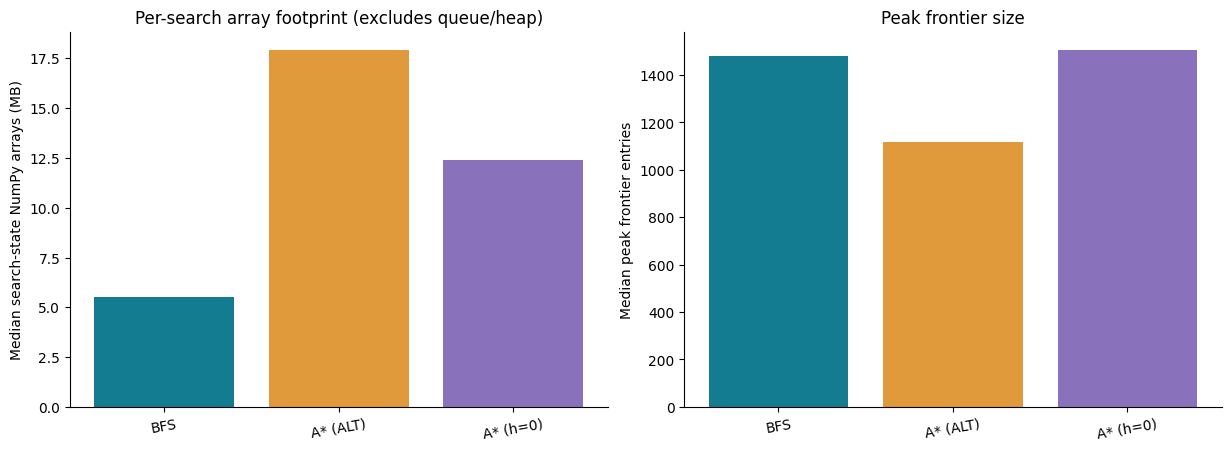

In [13]:
space_summary = (per_route.groupby('algorithm',as_index=False)
    .agg(median_search_arrays_MB=('search_arrays_MB','median'),
         max_search_arrays_MB=('search_arrays_MB','max'),
         median_peak_frontier=('peak_frontier','median'),
         max_peak_frontier=('peak_frontier','max')))
display(space_summary.round(2))
fig,axs=plt.subplots(1,2,figsize=(12.2,4.4),layout='constrained')
alg_order=['BFS','A* (ALT)','A* (h=0)']
space_sub=space_summary.set_index('algorithm').loc[alg_order]
axs[0].bar(alg_order,space_sub.median_search_arrays_MB,color=[PALETTE[a] for a in alg_order])
axs[0].set(ylabel='Median search-state NumPy arrays (MB)',title='Per-search array footprint (excludes queue/heap)')
axs[1].bar(alg_order,space_sub.median_peak_frontier,color=[PALETTE[a] for a in alg_order])
axs[1].set(ylabel='Median peak frontier entries',title='Peak frontier size')
for ax in axs: ax.tick_params(axis='x',rotation=10)
fig.savefig(FIGS/'06_working_memory_proxies.png',dpi=170,bbox_inches='tight')
plt.show()

Sampled per-query unique memory increase (Linux USS, not total RAM):


,category,algorithm,source_snap,target_snap,initial_RSS_MB,peak_RSS_MB,initial_unique_MB,peak_unique_MB,estimated_additional_unique_MB
0,Local,BFS,662101,659486,408.96,409.45,3.26,9.10,5.84
1,Local,A* (ALT),662101,659486,408.95,409.47,2.93,15.79,12.85
2,Regional,BFS,662101,954246,408.95,409.42,2.90,8.99,6.08
3,Regional,A* (ALT),662101,954246,408.95,409.66,2.91,36.71,33.80
4,Long-range,BFS,662101,1301725,408.95,409.42,2.94,9.15,6.21
5,Long-range,A* (ALT),662101,1301725,408.95,409.74,2.98,40.29,37.31


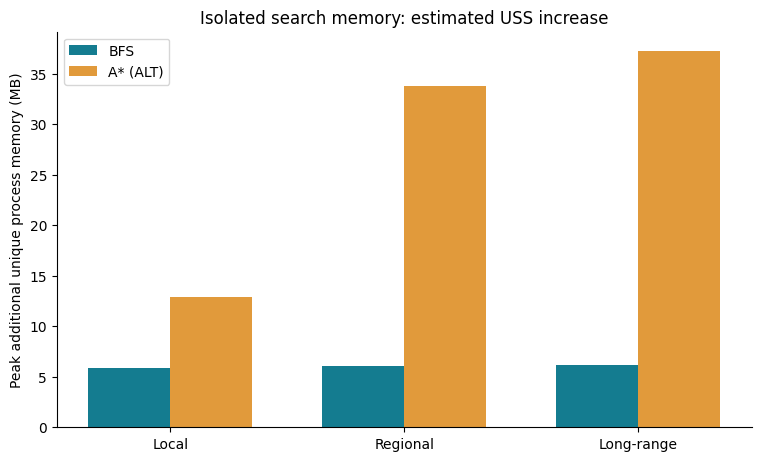

In [14]:
# Linux/Colab child processes run a single search; their memory is sampled by the parent.
# USS (unique-set size) accounts for private/COW pages better than RSS change alone.
import multiprocessing as mp

def _memory_child(send_conn, s, t, name):
    try:
        p = psutil.Process(os.getpid())
        start_info = p.memory_full_info()
        start_rss = int(start_info.rss)
        start_uss = int(getattr(start_info, 'uss', start_rss))
        result = METHODS[name](s,t)
        end_info = p.memory_full_info()
        end_uss = int(getattr(end_info, 'uss', end_info.rss))
        send_conn.send((start_rss,start_uss,end_uss,bool(result.found),int(result.hops)))
    except Exception as err:
        send_conn.send(('ERROR',repr(err)))
    finally:
        send_conn.close()

rss_rows=[]
if 'fork' in mp.get_all_start_methods():
    ctx=mp.get_context('fork')
    for category in CATEGORIES:
        case=next(c for c in route_cases if c['category']==category)
        for algorithm in ('BFS','A* (ALT)'):
            recv,send=ctx.Pipe(duplex=False)
            child=ctx.Process(target=_memory_child,args=(send,case['source_index'],case['target_index'],algorithm))
            child.start(); send.close()
            sampled_rss=[]; sampled_uss=[]
            monitor=psutil.Process(child.pid)
            while child.is_alive():
                try:
                    info=monitor.memory_full_info()
                    sampled_rss.append(int(info.rss))
                    sampled_uss.append(int(getattr(info,'uss',info.rss)))
                except (psutil.NoSuchProcess,psutil.ZombieProcess,PermissionError):
                    pass
                time.sleep(.004)
            child.join(timeout=20)
            if child.is_alive(): child.terminate(); child.join(); raise RuntimeError('Memory profiling process stalled')
            if not recv.poll(5): raise RuntimeError(f'No result from memory profiling for {algorithm}')
            payload=recv.recv(); recv.close()
            if payload[0]=='ERROR': raise RuntimeError(payload[1])
            start_rss,start_uss,end_uss,found,hops=payload
            assert found and hops==case['reference_hops']
            peak_rss=max(sampled_rss+[start_rss])
            peak_uss=max(sampled_uss+[start_uss,end_uss])
            rss_rows.append({'category':category,'algorithm':algorithm,
                             'source_snap':case['source_snap'], 'target_snap':case['target_snap'],
                             'initial_RSS_MB':start_rss/1e6, 'peak_RSS_MB':peak_rss/1e6,
                             'initial_unique_MB':start_uss/1e6, 'peak_unique_MB':peak_uss/1e6,
                             'estimated_additional_unique_MB':max(0,peak_uss-start_uss)/1e6})
    print('Sampled per-query unique memory increase (Linux USS, not total RAM):')
    display(pd.DataFrame(rss_rows).round(2))
    mem_df=pd.DataFrame(rss_rows)
    fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
    x=np.arange(len(CATEGORIES)); w=.35
    for offset,algo in [(-w/2,'BFS'),(w/2,'A* (ALT)')]:
        amounts=mem_df.set_index(['category','algorithm']).loc[[(cat,algo) for cat in CATEGORIES],'estimated_additional_unique_MB'].values
        ax.bar(x+offset,amounts,w,label=algo,color=PALETTE[algo])
    ax.set(xticks=x,xticklabels=list(CATEGORIES),ylabel='Peak additional unique process memory (MB)',
           title='Isolated search memory: estimated USS increase')
    ax.legend()
    fig.savefig(FIGS/'07_isolated_unique_memory.png',dpi=170,bbox_inches='tight')
    plt.show()
else:
    print('Memory profiling skipped: this OS does not provide fork. Array/frontier metrics remain valid.')
rss_df = pd.DataFrame(rss_rows)

## 13 · Heuristic ablation, statistical uncertainty, and amortized preparation cost

The `h=0` run uses the *same* A* code path except for replacing the ALT heuristic with zero. Its comparison with ALT tests whether guidance matters independently of BFS's FIFO queue vs A*'s priority queue. We also report a **source-cluster bootstrap confidence interval** for the median paired speedup. Six source nodes generate 18 dependent route cases, so treating all 18 as independent would overstate inferential certainty. These intervals describe this fixed experimental design, not a universal guarantee about all roads.

In [15]:
# A* h=0 ablation comparison
method_pivot = per_route.pivot(index='case_id',columns='algorithm',values='median_ms')
method_pivot['ALT_speedup_over_zero_h'] = method_pivot['A* (h=0)']/method_pivot['A* (ALT)']
print('Median speedup from heuristic vs the same search without a heuristic:',
      round(float(method_pivot.ALT_speedup_over_zero_h.median()),2),'x')

rng_boot=np.random.default_rng(SEED+98)
source_groups=[sub.speedup_BFS_over_Astar.to_numpy() for _,sub in paired.groupby('source_snap')]
B=3000
bootstrap_medians=np.empty(B)
for i in range(B):
    chosen=rng_boot.integers(0,len(source_groups),size=len(source_groups))
    bootstrap_medians[i]=np.median(np.concatenate([source_groups[j] for j in chosen]))
ci_low, ci_high=np.quantile(bootstrap_medians,[.025,.975])

# The break-even query count is a rough workload-specific estimate, not a general constant.
per_route_saved_ms = paired['median_ms_BFS']-paired['median_ms_A* (ALT)']
mean_saved_ms=float(per_route_saved_ms.mean())
break_even_queries = math.ceil(landmark_sec*1000/mean_saved_ms) if mean_saved_ms>0 else None
stats_df=pd.DataFrame([{
    'queries':len(paired), 'repetitions':REPETITIONS,
    'optimal_path_accuracy_BFS_pct':float(accuracy.loc[accuracy.algorithm=='BFS','Optimal-path accuracy (%)'].iloc[0]),
    'optimal_path_accuracy_Astar_pct':float(accuracy.loc[accuracy.algorithm=='A* (ALT)','Optimal-path accuracy (%)'].iloc[0]),
    'median_paired_speedup_BFS_over_Astar':float(paired.speedup_BFS_over_Astar.median()),
    'speedup_cluster_bootstrap_95pct_low':float(ci_low),
    'speedup_cluster_bootstrap_95pct_high':float(ci_high),
    'Astar_faster_cases':int((paired.speedup_BFS_over_Astar>1).sum()),
    'median_expanded_reduction_pct':float(paired.expanded_reduction_pct.median()),
    'median_ALT_vs_h0_speedup':float(method_pivot.ALT_speedup_over_zero_h.median()),
    'landmark_build_seconds':float(landmark_sec),
    'benchmark_wall_seconds':float(benchmark_wall_sec),
    'illustrative_landmark_break_even_queries':break_even_queries
}])
display(stats_df.T.rename(columns={0:'value'}))

Median speedup from heuristic vs the same search without a heuristic: 3.51 x


,value
queries,18.000000
repetitions,3.000000
optimal_path_accuracy_BFS_pct,100.000000
optimal_path_accuracy_Astar_pct,100.000000
median_paired_speedup_BFS_over_Astar,2.121408
speedup_cluster_bootstrap_95pct_low,1.719634
speedup_cluster_bootstrap_95pct_high,2.931342
Astar_faster_cases,14.000000
median_expanded_reduction_pct,93.439157
median_ALT_vs_h0_speedup,3.506971


## 14 · Complexity, limitations, and results interpretation

**Algorithmic complexity** (V = vertices, E = undirected edges, k = landmarks):

| Algorithm | Time (worst case) | Extra search space | Guarantee |
|---|---|---|---|
| BFS | `O(V+E)` | `O(V)` | Complete and shortest-hop optimal on finite graphs |
| A* ALT | `O((V+E) log V)` heap bound, plus heuristic evaluation | `O(V)` plus `O(kV)` offline landmark index | Complete and shortest-hop optimal with nonnegative edges and consistent ALT heuristic |
| Landmark construction | `O(k(V+E))` shortest-path graph work | `O(kV)` stored | Offline work, not included in the online route timings |

**Reading the results:** If ALT expands many fewer nodes yet occasionally runs slower, that is not a bug: priority-queue operations and heuristic evaluation have overhead. Graph/search costs are in hops, not physical miles or minutes. The latency figures apply only to this execution environment, and the 18 stratified queries are a deliberate evaluation set, not a population-wide success rate. No ML model is trained, and classification-specific accuracy/precision/recall/F1 are inapplicable.

**Evaluation quality:** independent SciPy reference for every route, edge-by-edge validation, repetitive randomized-order timings, shortest-hop agreement, disconnected/identical endpoint cases, heuristic consistency/admissibility tests, Dijkstra-equivalent ablation and offline preprocessing accounting.

## 15 · Export results, figures and runtime provenance

In [16]:
export_tables={
    'dataset_profile.csv':profile,
    'selected_route_cases.csv':cases_df,
    'all_162_timing_trials.csv':trials,
    'accuracy_and_correctness.csv':accuracy,
    'special_case_correctness.csv':special_df,
    'per_route_algorithm_results.csv':per_route,
    'paired_BFS_vs_Astar.csv':paired,
    'route_distance_summary.csv':summary_by_category,
    'working_memory_summary.csv':space_summary,
    'rss_profile_sample.csv':rss_df,
    'statistical_summary.csv':stats_df,
}
for filename,table in export_tables.items(): table.to_csv(RESULTS/filename,index=False)

notebook_wall_seconds=time.perf_counter()-TOTAL_STARTED
meta=pd.DataFrame([{
    'python':sys.version.split()[0], 'numpy':np.__version__,
    'scipy':__import__('scipy').__version__, 'platform':platform.platform(),
    'seed':SEED, 'sources':N_SOURCES, 'distance_bands':str(CATEGORIES),
    'repetitions':REPETITIONS, 'landmarks':N_LANDMARKS,
    'dataset_source':SNAP_FILE,
    'dataset_size_bytes':int(DATAFILE.stat().st_size),
    'parse_sec':parse_sec,'graph_build_sec':graph_sec,'landmark_build_sec':landmark_sec,
    'reference_sampling_sec':reference_sampling_sec,'benchmark_wall_sec':benchmark_wall_sec,
    'total_notebook_seconds':notebook_wall_seconds,
}])
meta.to_csv(RESULTS/'environment_and_runtime.csv',index=False)

zip_path=WORK/'Texas_RoadNet_BFS_AStar_Colab_Results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in sorted(RESULTS.rglob('*')):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(RESULTS)))
print(f'Saved {len(export_tables)+1} CSV tables and {len(list(FIGS.glob("*.png")))} figures.')
print(f'Complete notebook runtime: {notebook_wall_seconds/60:.2f} minutes ({notebook_wall_seconds:.1f} s).')
print('Result package:',zip_path,'| size MB:',round(zip_path.stat().st_size/1e6,2))

if 'google.colab' in sys.modules:
    from google.colab import files
    print('Download your ZIP with: files.download(str(zip_path))')

Saved 12 CSV tables and 7 figures.
Complete notebook runtime: 2.57 minutes (154.3 s).
Result package: /mnt/data/Texas_RoadNet_BFS_AStar_Colab_Results.zip | size MB: 0.45


## 16 · Conclusion & citations

Run the entire notebook to generate the figures/tables above from scratch. The evidence supports a **correctness comparison** (both BFS and consistent-heuristic ALT A* should return minimum-hop solutions) and a **search-efficiency comparison** (typically different numbers of expanded nodes, frontier sizes and execution times). The exact speedups depend on the 18 sampled routes and the current hardware; do not copy numbers from another run into a report without disclosing their origin.

**Sources:**
1. Stanford SNAP, [Texas road network dataset and statistics](https://snap.stanford.edu/data/roadNet-TX.html).
2. P. Hart, N. Nilsson and B. Raphael (1968), *A Formal Basis for the Heuristic Determination of Minimum Cost Paths*, IEEE Transactions on Systems Science and Cybernetics (A*).
3. A. Goldberg and C. Harrelson (2005), *Computing the Shortest Path: A* Search Meets Graph Theory*, SODA (landmark/triangle-inequality heuristic).
4. SciPy documentation, [`scipy.sparse.csgraph.shortest_path`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.shortest_path.html) — used solely for independent reference distances and offline landmark precomputation.

**Deliverable:** `Texas_RoadNet_BFS_AStar_Final_Colab.ipynb` plus the optional ZIP generated by the final cell. The notebook is independently executable in a fresh Google Colab runtime and does not need the interactive dashboard.